---
format:
  html:
    code-fold: false
    embed-resources: true
execute:
  echo: true
---

## Practice Activity 7-1: Association Rules Mining

In the reading you analyzed transactions from a bakery. In this activity you will carry out a very similar analysis for purchases from a grocery store.

In [6]:
import pandas as pd

from plotnine import *

from mlxtend.frequent_patterns import apriori, association_rules

# to stop an annoying warning
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning, module="jupyter_client")

## Groceries data set

- One month (30 days) of real point-of-sale transactions from a grocery store.
- 9,835 transactions (baskets).
- 169 product categories, such as whole milk, yogurt, bottled beer, etc.
- Source: the data set `Groceries` in the R package `arules`, provided by Hahsler, Hornik, and Reutterer. The copy we use is a plain-text version hosted on GitHub.


The file format is different from the bakery file. The bakery file had one row per item bought. This file has **one line per transaction**, and each line is a comma-separated list of the items in that basket. Different baskets have different numbers of items.

The next cell reads each line into a single text column. (Normal CSV reading expects every row to have the same number of columns, so we read each line as one string, using a separator `"|"` that never occurs in the file.)

In [7]:
import csv

raw = pd.read_csv(
    "https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/groceries.csv",
    header=None,             # the file has no header row: line 1 is already a transaction
    names=["basket"],        # name the one column we create
    sep="|",                 # "|" never appears in this file, so each whole line lands in one column
    quoting=csv.QUOTE_NONE,  # treat any quote characters as ordinary text
)

In [8]:
raw

,basket
0,"citrus fruit,semi-finished bread,margarine,rea..."
1,"tropical fruit,yogurt,coffee"
2,whole milk
3,"pip fruit,yogurt,cream cheese ,meat spreads"
4,"other vegetables,whole milk,condensed milk,lon..."
...,...
9830,"sausage,chicken,beef,hamburger meat,citrus fru..."
9831,cooking chocolate
9832,"chicken,citrus fruit,other vegetables,butter,y..."
9833,"semi-finished bread,bottled water,soda,bottled..."


We'll start with the data in long format like in the reading.

- Make a column `basket_id` from the row number (`raw.index`).
- Split the text in `raw["basket"]` at the commas, using `.str.split(",")`. This produces a *list* of items in each row.
- Use `.explode(...)` on the column of lists to get one row per item.
- Keep only `basket_id` and `item`, and use `.reset_index(drop=True)`.
- Trim spaces

In [9]:
long = (
    raw
    .assign(basket_id=raw.index)                    # use the row number as the basket ID
    .assign(item=raw["basket"].str.split(","))      # "milk,bread" becomes ["milk", "bread"]
    .explode("item")                                # one row per (basket, item)
    [["basket_id", "item"]]                         # keep only the two columns we need
    .reset_index(drop=True)                         # renumber the rows 0, 1, 2, ...
)

long["item"] = long["item"].str.strip()             # remove stray leading/trailing spaces

long

,basket_id,item
0,0,citrus fruit
1,0,semi-finished bread
2,0,margarine
3,0,ready soups
4,1,tropical fruit
...,...,...
43362,9834,chicken
43363,9834,tropical fruit
43364,9834,other vegetables
43365,9834,vinegar


1. Build the transaction-by-item table `basket`. There should be one row per basket, one column per item, with `True` if the item is in the basket and `False` otherwise.

In [ ]:
basket = pd.crosstab(long["basket_id"], long["item"]) > 0
basket.iloc[:5, :6]

(9835, 169)


item,Instant food products,UHT-milk,abrasive cleaner,artif. sweetener,baby cosmetics,baby food
basket_id,,,,,,
0,False,False,False,False,False,False
1,False,False,False,False,False,False
2,False,False,False,False,False,False
3,False,False,False,False,False,False
4,False,False,False,False,False,False


2.  Compute the size (number of items) of each basket and store it in `basket_sizes`.

In [13]:
basket_sizes = basket.sum(axis = 1)
basket_sizes

basket_id
0        4
1        3
2        1
3        4
4        4
        ..
9830    17
9831     1
9832    10
9833     4
9834     5
Length: 9835, dtype: int64

3. Summarize the distribution of the number of items.

In [14]:
basket_sizes.describe()

count    9835.000000
mean        4.409456
std         3.589385
min         1.000000
25%         2.000000
50%         3.000000
75%         6.000000
max        32.000000
dtype: float64

4. Compute the support of every item, sorted from largest to smallest, and store it in `item_support`. Then make a horizontal bar chart of the 15 most popular items.

In [16]:
basket_support = basket.mean().sort_values(ascending=False)
basket_support.round(3)

item
whole milk               0.256
other vegetables         0.193
rolls/buns               0.184
soda                     0.174
yogurt                   0.140
                         ...  
bags                     0.000
kitchen utensil          0.000
preservation products    0.000
baby food                0.000
sound storage medium     0.000
Length: 169, dtype: float64

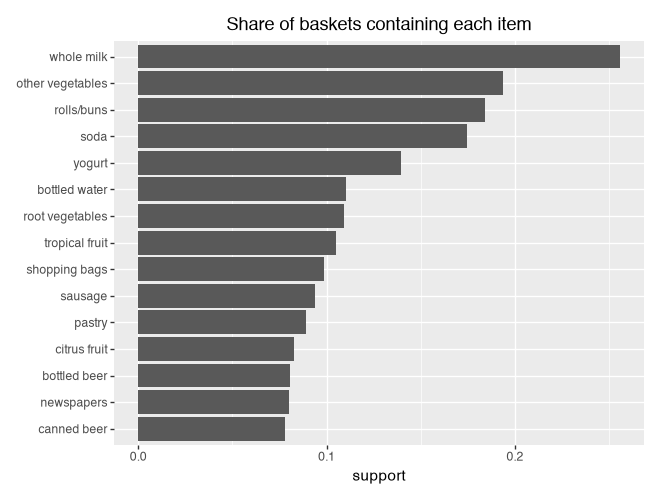

In [19]:
support_df = (
    basket_support
    .sort_values(ascending = False)
    .head(15)
    .reset_index()
)
support_df.columns = ["basket", "support"]
support_df["basket"] = pd.Categorical(support_df["basket"], categories=support_df["basket"][::-1])   # keep the order in the plot #reorder the artist according to the mean

(ggplot(support_df, aes(x="basket", y="support"))
 + geom_col()
 + coord_flip()
 + labs(title="Share of baskets containing each item", x="", y="support"))

5. Consider the basket sizes and the item supports. Which item is most popular, and in what percentage of baskets does it appear? Which items are most common? What does this suggest about the "popular items co-occur just by chance" problem discussed in the reading?

Whole milk is most popular and it appears in 25.6% of baskets. Some other items that are also common are other veegtables (19.4%), rolls/buns(18.4%), soda(17.4%), and yogurt(14%). This matters because popular items can appear together even if there is no especially meaningful relationship between them. Baskets containing whole milk can have high support because whole milk is popular. 

6. Consider the rule **{yogurt} → {whole milk}**. Compute and interpret the confidence of this rule.


In [20]:
confidence_yogurt_to_milk = (
    basket.loc[basket["yogurt"], "whole milk"].mean()
)

confidence_yogurt_to_milk

np.float64(0.40160349854227406)

7. Compute and interpret the **lift** of {yogurt} → {whole milk}.

In [21]:
confidence_yogurt_to_milk / basket_support["whole milk"]

np.float64(1.5717351405345266)

8. Now compute and interpret the confidence and lift for the rule {whole milk} → {yogurt}.

In [22]:
confidence_milk_to_yogurt = (
    basket.loc[basket["whole milk"], "yogurt"].mean()
)

lift_milk_to_yogurt = (
    confidence_milk_to_yogurt / basket_support["yogurt"]
)

confidence_milk_to_yogurt, lift_milk_to_yogurt

(np.float64(0.2192598487863112), np.float64(1.5717351405345266))

9. Write two functions.

- `support(items, onehot)`: returns the share of baskets that contain **all** of the items in the list `items`.
- `rule_metrics(antecedent, consequent, onehot)`: returns a Pandas Series with the `support`, `confidence`, and `lift` of the rule `antecedent -> consequent`. Both `antecedent` and `consequent` are *lists* of items.

Test the functions on `["yogurt"]` → `["whole milk"]`. The values should match the ones you computed earlier.

In [23]:
def support(items, onehot):
    """Share of baskets containing every item in items."""
    return onehot[items].all(axis=1).mean()


def rule_metrics(antecedent, consequent, onehot):
    """Support, confidence, and lift for antecedent → consequent."""
    antecedent_support = support(antecedent, onehot)
    consequent_support = support(consequent, onehot)
    rule_support = support(antecedent + consequent, onehot)

    confidence = rule_support / antecedent_support
    lift = confidence / consequent_support

    return pd.Series({
        "support": rule_support,
        "confidence": confidence,
        "lift": lift
    })

In [24]:
rule_metrics(["yogurt"], ["whole milk"], basket)

support       0.056024
confidence    0.401603
lift          1.571735
dtype: float64

10. Whole milk is in about a quarter of all baskets. Consider the rules `{X} → {whole milk}` for the five antecedents `X` in the next cell. Before running anything, predict: for which of these will the lift be **above 1**? For which might the confidence look decent but the lift be **close to or below 1**? Just think about this before proceeding.

I'm guessing yogurt, other vegetables, and rolls could be associated with whole milk since they are common "grocery" store items. Bottled water or soda may be near 1. 

In [25]:
antecedents = pd.Series(["yogurt", "rolls/buns", "bottled water", "soda", "other vegetables"])

11. Compute the support, confidence, and lift of `{X} → {whole milk}` for each of the five antecedents above, and display the results sorted by lift (largest first). Compare to your predictions. Hint: Use `apply` with `lambda` on the Series of antecedents.


In [27]:
results = antecedents.apply(
    lambda x: rule_metrics([x], ["whole milk"], basket)
)

results.insert(0, "antecedent", antecedents)

results.sort_values("lift" , ascending=False)

,antecedent,support,confidence,lift
0,yogurt,0.056024,0.401603,1.571735
4,other vegetables,0.074835,0.386758,1.513634
2,bottled water,0.034367,0.310948,1.216940
1,rolls/buns,0.056634,0.307905,1.205032
3,soda,0.040061,0.229738,0.899112


12. Run `apriori` on `basket` with `min_support=0.01` and store the result in `frequent_itemsets`. Then add a column `n_items` giving the number of items in each itemset.

In [28]:
frequent_itemsets = apriori(
    basket,
    min_support=0.01,
    use_colnames=True
)

frequent_itemsets["n_items"] = frequent_itemsets["itemsets"].apply(len)

frequent_itemsets

,support,itemsets,n_items
0,0.033452,(UHT-milk),1
1,0.017692,(baking powder),1
2,0.052466,(beef),1
3,0.033249,(berries),1
4,0.026029,(beverages),1
...,...,...,...
328,0.011998,"(root vegetables, tropical fruit, whole milk)",3
329,0.014540,"(root vegetables, whole milk, yogurt)",3
330,0.010473,"(soda, whole milk, yogurt)",3
331,0.015150,"(tropical fruit, whole milk, yogurt)",3


13. Generate the rules with `make_rules`, keeping rules with confidence of at least 0.20. Store them in `rules` and print how many there are.

In [29]:
rules = association_rules(
    frequent_itemsets,
    metric="confidence",
    min_threshold=0.20,
    num_itemsets=len(basket)
)

print(len(rules))

234


14. Make the rules easier to read. Create a copy `rules_display` of `rules` and add three columns:

- `antecedent`: the antecedent items as text, e.g. `"tropical fruit, yogurt"`
- `consequent`: the consequent items as text
- `transactions`: the number of baskets that contain the whole rule (support times the number of baskets, rounded to an integer)

Then display the columns `antecedent`, `consequent`, `support`, `confidence`, `lift`, `transactions` for the first 8 rules.

In [30]:
rules_display = rules.copy()

rules_display["antecedent"] = rules_display["antecedents"].apply(
    lambda items: ", ".join(sorted(items))
)

rules_display["consequent"] = rules_display["consequents"].apply(
    lambda items: ", ".join(sorted(items))
)

rules_display["transactions"] = (
    rules_display["support"] * len(basket)
).round().astype(int)

rules_display[
    [
        "antecedent",
        "consequent",
        "support",
        "confidence",
        "lift",
        "transactions"
    ]
].head(8)

,antecedent,consequent,support,confidence,lift,transactions
0,beef,other vegetables,0.019725,0.375969,1.943066,194
1,beef,rolls/buns,0.013625,0.259690,1.411858,134
2,beef,root vegetables,0.017387,0.331395,3.040367,171
3,beef,whole milk,0.021251,0.405039,1.585180,209
4,beef,yogurt,0.011693,0.222868,1.597601,115
5,berries,other vegetables,0.010269,0.308869,1.596280,101
6,berries,whole milk,0.011795,0.354740,1.388328,116
7,berries,yogurt,0.010574,0.318043,2.279848,104


15. Show the 10 rules with the highest **confidence**. What do the highest-confidence rules have in common? Why is confidence alone a poor guide here?

In [31]:
rules_display[
    [
        "antecedent",
        "consequent",
        "support",
        "confidence",
        "lift",
        "transactions"
    ]
].sort_values("confidence", ascending=False).head(10)

,antecedent,consequent,support,confidence,lift,transactions
157,"citrus fruit, root vegetables",other vegetables,0.010371,0.586207,3.029608,102
184,"root vegetables, tropical fruit",other vegetables,0.012303,0.584541,3.020999,121
164,"curd, yogurt",whole milk,0.010066,0.582353,2.279125,99
153,"butter, other vegetables",whole milk,0.011490,0.573604,2.244885,113
221,"root vegetables, tropical fruit",whole milk,0.011998,0.570048,2.230969,118
225,"root vegetables, yogurt",whole milk,0.014540,0.562992,2.203354,143
165,"domestic eggs, other vegetables",whole milk,0.012303,0.552511,2.162336,121
233,"whipped/sour cream, yogurt",whole milk,0.010880,0.524510,2.052747,107
214,"rolls/buns, root vegetables",whole milk,0.012710,0.523013,2.046888,125
171,"other vegetables, pip fruit",whole milk,0.013523,0.517510,2.025351,133


The highest confidence rules have a very small number of transactions and a very popular consequent like whole milk. Confidence alone can be misleading because it doesn't account for how common the consequent already is. If an item appears in many baskets, it can have seemingly high confidence by chance. 

16. Show the 10 rules with the highest **lift**. Compare this list with the highest-confidence list. What kinds of products appear now? Look at the `support` and `transactions` columns: how much evidence is each of these rules based on?

In [32]:
rules_display[
    [
        "antecedent",
        "consequent",
        "support",
        "confidence",
        "lift",
        "transactions"
    ]
].sort_values("lift", ascending=False).head(10)

,antecedent,consequent,support,confidence,lift,transactions
158,"citrus fruit, other vegetables",root vegetables,0.010371,0.359155,3.295045,102
209,"other vegetables, yogurt",whipped/sour cream,0.010168,0.234192,3.267062,100
186,"other vegetables, tropical fruit",root vegetables,0.012303,0.342776,3.144780,121
2,beef,root vegetables,0.017387,0.331395,3.040367,171
157,"citrus fruit, root vegetables",other vegetables,0.010371,0.586207,3.029608,102
184,"root vegetables, tropical fruit",other vegetables,0.012303,0.584541,3.020999,121
189,"other vegetables, whole milk",root vegetables,0.023183,0.309783,2.842082,228
190,root vegetables,"other vegetables, whole milk",0.023183,0.212687,2.842082,228
155,butter,"other vegetables, whole milk",0.011490,0.207339,2.770630,113
163,"curd, whole milk",yogurt,0.010066,0.385214,2.761356,99


The high lift involves more specific combinations, like vegetables, fruit, whipped cream, butter, beef and yogurt. These products occur together more than individually. The evidence is limited, though. The support is about 1 to 2.3% which is not a lot of baskets. The results are meaningful but only based on small subsets. 

17. Create `interesting_rules`: the rules with **confidence of at least 0.30 and lift of at least 1.5**, sorted by lift (largest first).


In [33]:
interesting_rules = (
    rules_display
    .query("confidence >= 0.30 and lift >= 1.5")
    .sort_values("lift", ascending=False)
)

interesting_rules[
    [
        "antecedent",
        "consequent",
        "support",
        "confidence",
        "lift",
        "transactions"
    ]
]

,antecedent,consequent,support,confidence,lift,transactions
158,"citrus fruit, other vegetables",root vegetables,0.010371,0.359155,3.295045,102
186,"other vegetables, tropical fruit",root vegetables,0.012303,0.342776,3.144780,121
2,beef,root vegetables,0.017387,0.331395,3.040367,171
157,"citrus fruit, root vegetables",other vegetables,0.010371,0.586207,3.029608,102
184,"root vegetables, tropical fruit",other vegetables,0.012303,0.584541,3.020999,121
...,...,...,...,...,...,...
89,onions,whole milk,0.012100,0.390164,1.526965,119
72,hygiene articles,whole milk,0.012811,0.388889,1.521975,126
17,brown bread,whole milk,0.025216,0.388715,1.521293,248
105,other vegetables,whole milk,0.074835,0.386758,1.513634,736


18. Choose **one** rule from the table and interpret its **support**, **confidence**, and **lift** with numbers, as you did for {yogurt} → {whole milk}.

The rule {citrus fruit, other vegetables} → {root vegetables} has support of about 1.04%, meaning roughly 102 baskets contained all three items. Its confidence is about 35.9%, meaning that among baskets containing citrus fruit and other vegetables, 35.9% also contain root vegetables. Its lift is about 3.3, so these baskets are about 3.3 times as likely to contain root vegetables as a typical basket. This indicates a fairly strong association, although it is based on only about 102 transactions.

19. The manager wants to **increase sales of yogurt**. Which products should the store link to yogurt (shelf placement, a joint promotion, a recommendation)?

In [34]:
yogurt_rules = (
    rules_display[
        rules_display["consequents"].apply(lambda items: "yogurt" in items)
    ]
    .sort_values(["lift", "support"], ascending=False)
)

yogurt_rules[
    [
        "antecedent",
        "consequent",
        "support",
        "confidence",
        "lift",
        "transactions"
    ]
]

,antecedent,consequent,support,confidence,lift,transactions
163,"curd, whole milk",yogurt,0.010066,0.385214,2.761356,99
229,"tropical fruit, whole milk",yogurt,0.015150,0.358173,2.567516,149
207,"other vegetables, whipped/sour cream",yogurt,0.010168,0.352113,2.524073,100
201,"other vegetables, tropical fruit",yogurt,0.012303,0.342776,2.457146,121
232,"whipped/sour cream, whole milk",yogurt,0.010880,0.337539,2.419607,107
161,"citrus fruit, whole milk",yogurt,0.010269,0.336667,2.413350,101
47,curd,yogurt,0.017285,0.324427,2.325615,170
7,berries,yogurt,0.010574,0.318043,2.279848,104
43,cream cheese,yogurt,0.012405,0.312821,2.242412,122
210,"other vegetables, whole milk",yogurt,0.022267,0.297554,2.132979,219


I'd use curd near yogurt or offer a curd-yogurt promotion, and show yogurt reccommendations for cream cheese and berry buyers. 

---
## References and attribution


- Hahsler, M., Gr&uuml;n, B., and Hornik, K. (2005). arules: A computational environment for mining association rules and frequent item sets. *Journal of Statistical Software*, 14(15). (The R package that distributes the data.)
- Data copy: GitHub repository `stedy/Machine-Learning-with-R-datasets` (`groceries.csv`), the data used in Lantz, B., *Machine Learning with R*.
- Raschka, S. (2018). MLxtend: Providing machine learning and data science utilities and extensions to Python's scientific computing stack. *Journal of Open Source Software*, 3(24), 638. <https://doi.org/10.21105/joss.00638>


**Preparation of this notebook:** drafted with the assistance of generative AI tools (ChatGPT and Claude).